# Bangla License Plate Deblurring - DeblurGAN (v1, 2018) Baseline
Original DeblurGAN (Kupyn et al., CVPR 2018): conditional GAN with a ResNet generator (9 residual blocks, global skip connection) and a single-scale PatchGAN critic. Trained with WGAN-GP adversarial loss + VGG19 conv3_3 perceptual loss (lambda = 100). Same data, split, image size, optimizer settings and metrics as the DeblurGAN-v2 notebook so the comparison stays fair.

## Libraries

In [1]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import models
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

device = torch.device("cuda")
torch.backends.cudnn.benchmark = True
print("GPU:", torch.cuda.get_device_name(0))

GPU: NVIDIA GeForce RTX 3060


d:\thesis model training\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Paths and settings

In [2]:
CLEAN_DIR = r"D:\_deblur gan\new dataset\fixed cropped"
GAUSSIAN_DIR = r"D:\_deblur gan\new dataset\light_gaussian_blurred"
MOTION_DIR = r"D:\_deblur gan\new dataset\light_motion_blurred"

# same as the v2 notebook
IMG_H = 128
IMG_W = 256
BATCH_SIZE = 8
EPOCHS = 20
VAL_SPLIT = 0.1
SEED = 42

# DeblurGAN v1 settings (from the paper / official repo)
NGF = 64            # generator base channels
NDF = 64            # critic base channels
N_BLOCKS = 9        # residual blocks in the generator
LR_G = 1e-4
LR_D = 1e-4
N_CRITIC = 5        # critic updates per generator update (WGAN-GP)
LAMBDA_GP = 10      # gradient penalty weight
LAMBDA_CONTENT = 100  # perceptual loss weight

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## Dataset (images are loaded into RAM once, so training is faster)

In [3]:
valid_ext = (".png", ".jpg", ".jpeg", ".bmp")

clean_names = sorted([f for f in os.listdir(CLEAN_DIR) if f.lower().endswith(valid_ext)])
random.shuffle(clean_names)

val_count = int(len(clean_names) * VAL_SPLIT)
val_names = clean_names[:val_count]
train_names = clean_names[val_count:]


def make_pairs(names):
    pairs = []
    for name in names:
        for blur_dir in (GAUSSIAN_DIR, MOTION_DIR):
            blur_path = os.path.join(blur_dir, name)
            if os.path.exists(blur_path):
                pairs.append((blur_path, os.path.join(CLEAN_DIR, name)))
    return pairs


class PlateDataset(Dataset):
    def __init__(self, pairs):
        self.blur = []
        self.clean = []
        for blur_path, clean_path in tqdm(pairs):
            self.blur.append(self.load(blur_path))
            self.clean.append(self.load(clean_path))

    def __len__(self):
        return len(self.blur)

    def load(self, path):
        img = Image.open(path).convert("RGB").resize((IMG_W, IMG_H), Image.BICUBIC)
        return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)

    def __getitem__(self, i):
        return self.blur[i].float() / 127.5 - 1, self.clean[i].float() / 127.5 - 1


train_pairs = make_pairs(train_names)
val_pairs = make_pairs(val_names)

train_loader = DataLoader(PlateDataset(train_pairs), batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True, drop_last=True)
val_loader = DataLoader(PlateDataset(val_pairs), batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print("clean images:", len(clean_names))
print("train pairs:", len(train_pairs))
print("val pairs:", len(val_pairs))

100%|██████████| 398/398 [00:08<00:00, 45.20it/s]

clean images: 1991
train pairs: 3584
val pairs: 398


## Generator (ResNet, 9 blocks)
c7s1-64 -> 2 x stride-2 downsampling -> 9 ResBlocks (with dropout) -> 2 x transposed-conv upsampling -> c7s1-3 -> tanh. The output is added to the input (global skip) so the network only learns the residual, exactly as in the paper.

In [4]:
class ResnetBlock(nn.Module):
    def __init__(self, dim, use_dropout=True):
        super().__init__()
        layers = [
            nn.ReflectionPad2d(1),
            nn.Conv2d(dim, dim, 3),
            nn.InstanceNorm2d(dim),
            nn.ReLU(True),
        ]
        if use_dropout:
            layers.append(nn.Dropout(0.5))
        layers += [
            nn.ReflectionPad2d(1),
            nn.Conv2d(dim, dim, 3),
            nn.InstanceNorm2d(dim),
        ]
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return x + self.block(x)


class ResnetGenerator(nn.Module):
    def __init__(self, ngf=64, n_blocks=9, use_dropout=True):
        super().__init__()

        layers = [
            nn.ReflectionPad2d(3),
            nn.Conv2d(3, ngf, 7),
            nn.InstanceNorm2d(ngf),
            nn.ReLU(True),
        ]

        # downsampling: 64 -> 128 -> 256 channels
        for i in range(2):
            mult = 2 ** i
            layers += [
                nn.Conv2d(ngf * mult, ngf * mult * 2, 3, stride=2, padding=1),
                nn.InstanceNorm2d(ngf * mult * 2),
                nn.ReLU(True),
            ]

        # residual blocks at 256 channels
        layers += [ResnetBlock(ngf * 4, use_dropout) for _ in range(n_blocks)]

        # upsampling: 256 -> 128 -> 64 channels
        for i in range(2):
            mult = 2 ** (2 - i)
            layers += [
                nn.ConvTranspose2d(ngf * mult, ngf * mult // 2, 3, stride=2, padding=1, output_padding=1),
                nn.InstanceNorm2d(ngf * mult // 2),
                nn.ReLU(True),
            ]

        layers += [
            nn.ReflectionPad2d(3),
            nn.Conv2d(ngf, 3, 7),
            nn.Tanh(),
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return torch.clamp(x + self.model(x), -1, 1)


def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)

## Critic (single-scale 70x70 PatchGAN)
DeblurGAN v1 has no local/global pair like v2. It uses one PatchGAN critic on the full image. No sigmoid, because WGAN-GP needs raw scores.

In [5]:
class PatchDiscriminator(nn.Module):
    def __init__(self, ndf=64):
        super().__init__()

        def block(in_ch, out_ch, stride, norm=True):
            layers = [nn.Conv2d(in_ch, out_ch, 4, stride, 1)]
            if norm:
                layers.append(nn.InstanceNorm2d(out_ch))
            layers.append(nn.LeakyReLU(0.2, True))
            return layers

        self.net = nn.Sequential(
            *block(3, ndf, 2, norm=False),
            *block(ndf, ndf * 2, 2),
            *block(ndf * 2, ndf * 4, 2),
            *block(ndf * 4, ndf * 8, 1),
            nn.Conv2d(ndf * 8, 1, 4, 1, 1),
        )

    def forward(self, x):
        return self.net(x)

## Loss functions and metrics (PSNR, SSIM, MAE)
WGAN-GP critic loss, WGAN generator loss, VGG19 conv3_3 perceptual loss. PSNR / SSIM / MAE are identical to the v2 notebook.

In [6]:
vgg = models.vgg19(weights=models.VGG19_Weights.DEFAULT).features[:15].to(device).eval()  # up to conv3_3
for p in vgg.parameters():
    p.requires_grad = False

vgg_mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
vgg_std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)


def perceptual_loss(fake, real):
    fake = ((fake + 1) / 2 - vgg_mean) / vgg_std
    real = ((real + 1) / 2 - vgg_mean) / vgg_std
    with torch.no_grad():
        real_feat = vgg(real)
    return F.mse_loss(vgg(fake), real_feat)


def gradient_penalty(D, real, fake):
    alpha = torch.rand(real.size(0), 1, 1, 1, device=real.device)
    mixed = (alpha * real + (1 - alpha) * fake).requires_grad_(True)
    score = D(mixed)
    grads = torch.autograd.grad(score.sum(), mixed, create_graph=True)[0]
    grad_norm = grads.flatten(1).norm(2, dim=1)
    return ((grad_norm - 1) ** 2).mean()


def ssim(fake, real, window=11, sigma=1.5):
    fake = (fake.clamp(-1, 1) + 1) / 2
    real = (real + 1) / 2
    coords = torch.arange(window, dtype=torch.float32, device=fake.device) - window // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    kernel = (g[:, None] * g[None, :]).expand(3, 1, window, window).contiguous()
    mu_f = F.conv2d(fake, kernel, groups=3)
    mu_r = F.conv2d(real, kernel, groups=3)
    var_f = F.conv2d(fake * fake, kernel, groups=3) - mu_f ** 2
    var_r = F.conv2d(real * real, kernel, groups=3) - mu_r ** 2
    cov = F.conv2d(fake * real, kernel, groups=3) - mu_f * mu_r
    c1 = 0.01 ** 2
    c2 = 0.03 ** 2
    score = ((2 * mu_f * mu_r + c1) * (2 * cov + c2)) / ((mu_f ** 2 + mu_r ** 2 + c1) * (var_f + var_r + c2))
    return score.mean(dim=(1, 2, 3))


def mae(fake, real):
    return ((fake.clamp(-1, 1) - real).abs() * 127.5).mean(dim=(1, 2, 3))


def evaluate(net, loader):
    net.eval()
    p_all, s_all, m_all = [], [], []
    with torch.no_grad():
        for blur, clean in loader:
            blur = blur.to(device)
            clean = clean.to(device)
            fake = net(blur)
            if isinstance(fake, (list, tuple)):
                fake = fake[0]
            fake = fake.clamp(-1, 1)
            mse = (((fake + 1) / 2 - (clean + 1) / 2) ** 2).mean(dim=(1, 2, 3))
            p_all.append(10 * torch.log10(1 / (mse + 1e-8)))
            s_all.append(ssim(fake, clean))
            m_all.append(mae(fake, clean))
    return torch.cat(p_all), torch.cat(s_all), torch.cat(m_all)

## Models, optimizers, schedulers

In [7]:
G = ResnetGenerator(NGF, N_BLOCKS).to(device)
D = PatchDiscriminator(NDF).to(device)
G.apply(init_weights)
D.apply(init_weights)

opt_g = torch.optim.Adam(G.parameters(), lr=LR_G, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(D.parameters(), lr=LR_D, betas=(0.5, 0.999))


def decay_rule(epoch):
    half = EPOCHS // 2
    if epoch < half:
        return 1.0
    return 1.0 - (epoch - half) / (EPOCHS - half)


sched_g = torch.optim.lr_scheduler.LambdaLR(opt_g, lr_lambda=decay_rule)
sched_d = torch.optim.lr_scheduler.LambdaLR(opt_d, lr_lambda=decay_rule)

print("generator params:", sum(p.numel() for p in G.parameters()) / 1e6, "M")
print("critic params:", sum(p.numel() for p in D.parameters()) / 1e6, "M")

generator params: 11.378179 M
critic params: 2.764737 M


## Blurry input metrics (reference before training)

In [8]:
p, s, m = evaluate(nn.Identity(), val_loader)
print(f"Blurry input | PSNR {p.mean():.2f} | SSIM {s.mean():.4f} | MAE {m.mean():.2f}")

Blurry input | PSNR 26.27 | SSIM 0.8171 | MAE 9.01


## Checkpoint setup

In [9]:
CKPT_DIR = "checkpoints_deblurgan_v1"
os.makedirs(CKPT_DIR, exist_ok=True)
LAST_PATH = os.path.join(CKPT_DIR, "last.pth")
BEST_PATH = os.path.join(CKPT_DIR, "best.pth")

start_epoch = 0
best_psnr = 0.0
history = {"g_loss": [], "d_loss": [], "w_dist": [], "val_psnr": [], "val_ssim": [], "val_mae": []}

RESUME = False

if RESUME and os.path.exists(LAST_PATH):
    ckpt = torch.load(LAST_PATH, map_location=device)
    G.load_state_dict(ckpt["G"])
    D.load_state_dict(ckpt["D"])
    opt_g.load_state_dict(ckpt["opt_g"])
    opt_d.load_state_dict(ckpt["opt_d"])
    sched_g.load_state_dict(ckpt["sched_g"])
    sched_d.load_state_dict(ckpt["sched_d"])
    history = ckpt["history"]
    best_psnr = ckpt["best_psnr"]
    start_epoch = ckpt["epoch"] + 1
    print("resumed from epoch", start_epoch)

## Training
Per batch: N_CRITIC critic updates (WGAN-GP) on the same batch, then one generator update with `-D(G(x)) + 100 * perceptual`. `w_dist` is the estimated Wasserstein distance, which should shrink as the generator improves.

In [10]:
for epoch in range(start_epoch, EPOCHS):
    G.train()
    D.train()
    g_sum = 0
    d_sum = 0
    w_sum = 0

    for blur, clean in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}"):
        blur = blur.to(device, non_blocking=True)
        clean = clean.to(device, non_blocking=True)

        # ---- critic ----
        for p_ in D.parameters():
            p_.requires_grad_(True)
        with torch.no_grad():
            fake = G(blur)

        for _ in range(N_CRITIC):
            opt_d.zero_grad()
            d_real = D(clean).mean()
            d_fake = D(fake).mean()
            gp = gradient_penalty(D, clean, fake)
            d_loss = d_fake - d_real + LAMBDA_GP * gp
            d_loss.backward()
            opt_d.step()

        # ---- generator ----
        for p_ in D.parameters():
            p_.requires_grad_(False)
        opt_g.zero_grad()
        fake = G(blur)
        adv = -D(fake).mean()
        content = perceptual_loss(fake, clean)
        g_loss = adv + LAMBDA_CONTENT * content
        g_loss.backward()
        opt_g.step()

        g_sum += g_loss.item()
        d_sum += d_loss.item()
        w_sum += (d_real - d_fake).item()

    sched_g.step()
    sched_d.step()

    p, s, m = evaluate(G, val_loader)
    val_psnr = p.mean().item()
    val_ssim = s.mean().item()
    val_mae = m.mean().item()

    history["g_loss"].append(g_sum / len(train_loader))
    history["d_loss"].append(d_sum / len(train_loader))
    history["w_dist"].append(w_sum / len(train_loader))
    history["val_psnr"].append(val_psnr)
    history["val_ssim"].append(val_ssim)
    history["val_mae"].append(val_mae)

    print(f"epoch {epoch + 1} | G loss {history['g_loss'][-1]:.4f} | D loss {history['d_loss'][-1]:.4f} | W-dist {history['w_dist'][-1]:.4f} | val PSNR {val_psnr:.2f} | SSIM {val_ssim:.4f} | MAE {val_mae:.2f}")

    if history["val_psnr"][-1] > best_psnr:
        best_psnr = history["val_psnr"][-1]
        torch.save(G.state_dict(), BEST_PATH)

    torch.save({
        "G": G.state_dict(),
        "D": D.state_dict(),
        "opt_g": opt_g.state_dict(),
        "opt_d": opt_d.state_dict(),
        "sched_g": sched_g.state_dict(),
        "sched_d": sched_d.state_dict(),
        "history": history,
        "best_psnr": best_psnr,
        "epoch": epoch,
    }, LAST_PATH)

Epoch 1/20: 100%|██████████| 448/448 [04:47<00:00,  1.56it/s]


epoch 1 | G loss 2780.8466 | D loss 84.5776 | W-dist -0.0000 | val PSNR 16.67 | SSIM 0.4618 | MAE 28.38


Epoch 2/20: 100%|██████████| 448/448 [04:29<00:00,  1.66it/s]


epoch 2 | G loss 1930.4366 | D loss 1.0961 | W-dist 0.0003 | val PSNR 22.63 | SSIM 0.6671 | MAE 12.93


Epoch 3/20: 100%|██████████| 448/448 [04:33<00:00,  1.64it/s]


...

epoch 18 | G loss 955.4257 | D loss -0.0234 | W-dist 0.0271 | val PSNR 27.29 | SSIM 0.8276 | MAE 7.87


Epoch 19/20: 100%|██████████| 448/448 [04:45<00:00,  1.57it/s]


epoch 19 | G loss 939.5691 | D loss -0.0345 | W-dist 0.0358 | val PSNR 27.53 | SSIM 0.8316 | MAE 7.68


Epoch 20/20: 100%|██████████| 448/448 [04:45<00:00,  1.57it/s]


epoch 20 | G loss 928.8733 | D loss -0.0385 | W-dist 0.0395 | val PSNR 27.43 | SSIM 0.8303 | MAE 7.77


## Training curves

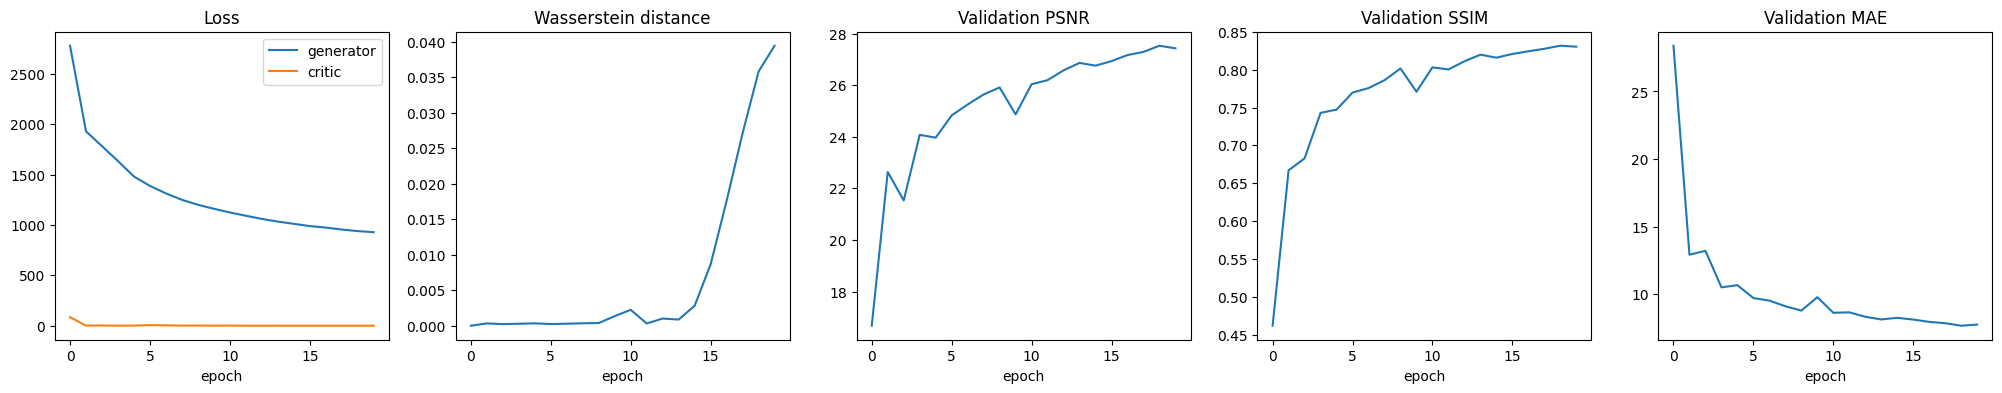

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(25, 4))
axes[0].plot(history["g_loss"], label="generator")
axes[0].plot(history["d_loss"], label="critic")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(history["w_dist"])
axes[1].set_title("Wasserstein distance")
axes[2].plot(history["val_psnr"])
axes[2].set_title("Validation PSNR")
axes[3].plot(history["val_ssim"])
axes[3].set_title("Validation SSIM")
axes[4].plot(history["val_mae"])
axes[4].set_title("Validation MAE")
for ax in axes:
    ax.set_xlabel("epoch")
plt.show()

## Visual results

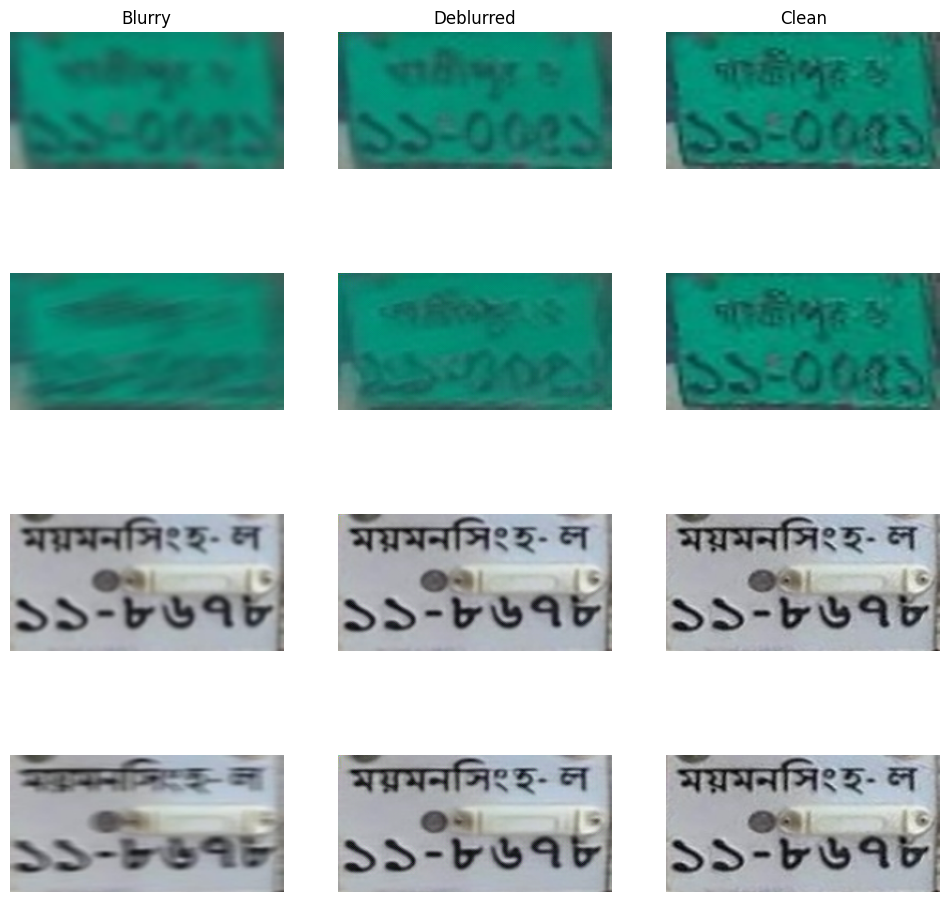

In [12]:
G.eval()
blur, clean = next(iter(val_loader))
with torch.no_grad():
    fake = G(blur.to(device)).clamp(-1, 1).cpu()


def show(t):
    return ((t.permute(1, 2, 0) + 1) / 2).clamp(0, 1).numpy()


n = min(4, blur.size(0))
fig, axes = plt.subplots(n, 3, figsize=(12, 3 * n), squeeze=False)
for i in range(n):
    axes[i][0].imshow(show(blur[i]))
    axes[i][1].imshow(show(fake[i]))
    axes[i][2].imshow(show(clean[i]))
    for j in range(3):
        axes[i][j].axis("off")
axes[0][0].set_title("Blurry")
axes[0][1].set_title("Deblurred")
axes[0][2].set_title("Clean")
plt.show()

Final evaluation with the best weights

In [13]:
G.load_state_dict(torch.load(BEST_PATH, map_location=device))
p, s, m = evaluate(G, val_loader)
p, s, m = p.cpu().numpy(), s.cpu().numpy(), m.cpu().numpy()

is_motion = np.array([os.path.dirname(b) == MOTION_DIR for b, _ in val_pairs])
groups = {"all": np.ones(len(p), dtype=bool), "gaussian": ~is_motion, "motion": is_motion}

for name, mask in groups.items():
    print(f"{name:9s} | PSNR {p[mask].mean():.2f} | SSIM {s[mask].mean():.4f} | MAE {m[mask].mean():.2f}")

all       | PSNR 27.53 | SSIM 0.8316 | MAE 7.68
gaussian  | PSNR 29.37 | SSIM 0.8788 | MAE 6.13
motion    | PSNR 25.69 | SSIM 0.7844 | MAE 9.23
